# V39: what does our validation population represent?

Zero exact model-ID overlap remains after near-exact native token-length
matching. However, the frozen composite criterion does not pass: only one
non-identity standardized covariate crosses0.25after the single-turn/length
adjustment; two were required. No preference labels or prediction-quality
analysis is part of this audit. Identities are diagnostic only.

Original teacher training overlap and later-source selection remain distinct
limitations. A source gap is not a demonstrated score gain. The first result is
preserved; a separate correction fixes constant-column floating-point SMD and
tiny total-variation roundoff, without changing the decision.

Fable/high independent review is requested but unavailable under the current
account; reviewer selection is pending. This notebook does not substitute for it.

[Protocol](../docs/SPAN_039_PLAN.md) · [Result](../docs/SPAN_039_RESULTS.md).

Frozen decision: no_predeclared_material_mismatch


,rows,turns,log_total_chars,log_prompt_chars,log_answer_chars,answer_imbalance,nonascii_share,code_fence,markdown_heading,math_delimiter,math_request,risk_context,checked_claim,nonzero_arithmetic
view,,,,,,,,,,,,,,
original_all,57477,1.244219,7.599679,4.760246,7.425727,0.299233,0.005397,0.119143,0.048785,0.047201,0.092855,0.155645,0.004297,0.001270
original_single_turn,49938,1.000000,7.474434,4.653211,7.291799,0.305492,0.005109,0.112580,0.045697,0.044055,0.087669,0.139733,0.004325,0.001282
later_all,11215,1.000000,8.577409,4.891075,8.496765,0.316024,0.012813,0.275078,0.703255,0.188230,0.109942,0.301739,0.001605,0.000089
later_matched1024,1024,1.000000,7.589542,4.370301,7.484453,0.320657,0.010911,0.130859,0.414062,0.080078,0.057617,0.132812,0.002930,0.000000
original_uniform512,512,1.277344,7.596575,4.695848,7.460928,0.304845,0.005359,0.123047,0.056641,0.046875,0.103516,0.144531,0.005859,0.003906


Exact model-ID support:


,exact_or_prefix,original_unique,source_unique,shared,overlap_mass,total_variation,js_distance_base2,both_exact_ids_supported
view,,,,,,,,
later_all,exact_model_id,64,48,0,0.0,1.0,1.0,0.0
later_matched1024,exact_model_id,64,47,0,0.0,1.0,1.0,0.0
later_length_standardized,exact_model_id,64,48,0,0.0,1.0,1.0,0.0


Native token histogram TV: 0.0013337706006315499
Length-weight ESS / missing target-bin mass: 4410.1975308970805 0.0


turns                 0.000000
log_total_chars       0.049769
log_prompt_chars     -0.202426
log_answer_chars      0.100907
answer_imbalance      0.092137
nonascii_share        0.206449
code_fence            0.095516
markdown_heading      0.918481
math_delimiter        0.225975
math_request         -0.087988
risk_context         -0.009188
checked_claim        -0.027752
nonzero_arithmetic   -0.035331
Name: SMD after fixed length standardization, dtype: float64

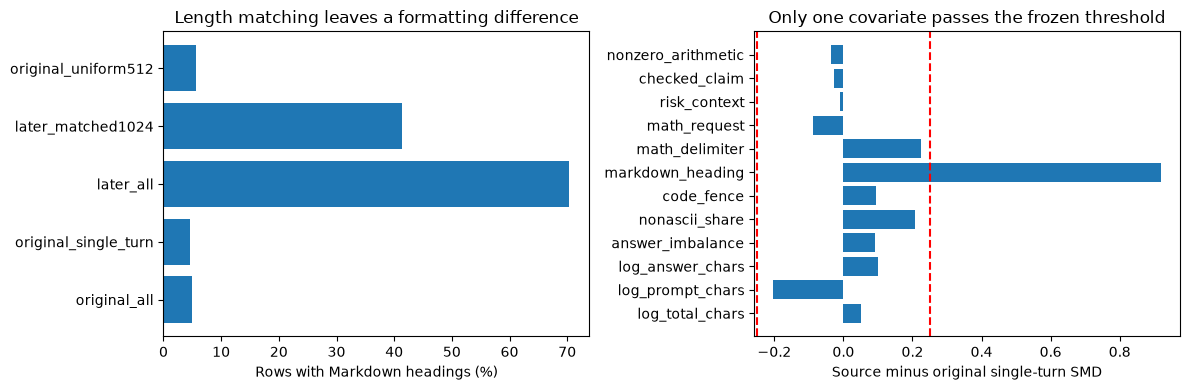

Numerical correction: {'at': '2026-11-09T16:32:11.321851+00:00', 'original_result_sha256': 'ef2d9f6cdf25f4bb9485076066ee1b82acd198424f30201b0833ab2d83a335a5', 'first_result_preserved': True, 'no_new_data_or_quality_fit': True, 'gate_and_decision_unchanged': True, 'changed_fields': [{'field': 'view_summaries.original_single_turn.means.turns', 'before': 0.9999999999999998, 'after': 1.0}, {'field': 'view_summaries.original_single_turn.stds.turns', 'before': 2.2204460492503128e-16, 'after': 0.0}, {'field': 'view_summaries.later_all.means.turns', 'before': 1.0000000000000002, 'after': 1.0}, {'field': 'view_summaries.later_all.stds.turns', 'before': 2.220446049250313e-16, 'after': 0.0}, {'field': 'length_standardization.smd_vs_original_single.turns', 'before': 1.4142135623730951, 'after': 0.0}, {'field': 'model_comparisons.later_length_standardized.total_variation', 'before': 1.0000000000000078, 'after': 1.0}], 'source_sha256': {'src/arena/span039_population_math.py': '279c27c0db75b79b2f97b1

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_039'
r=json.loads((PUB/'H81_corrected_results.json').read_text())
print('Frozen decision:',r['decision'])
display(pd.DataFrame([dict(view=k,rows=v['rows'],**v['means']) for k,v in r['view_summaries'].items()]).set_index('view'))
print('Exact model-ID support:')
display(pd.DataFrame([{k:v for k,v in d.items() if k not in ['original_top10','source_top10']}|dict(view=n) for n,d in r['model_comparisons'].items()]).set_index('view'))
print('Native token histogram TV:',r['matched_native_length_total_variation'])
print('Length-weight ESS / missing target-bin mass:',r['length_standardization']['ess'],r['length_standardization']['missing_target_bin_mass'])
smd=r['length_standardization']['smd_vs_original_single']
display(pd.Series(smd,name='SMD after fixed length standardization'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
names=list(r['view_summaries'])
axes[0].barh(names,[100*r['view_summaries'][n]['means']['markdown_heading'] for n in names])
axes[0].set_xlabel('Rows with Markdown headings (%)')
axes[0].set_title('Length matching leaves a formatting difference')
keys=[k for k in smd if k!='turns']
axes[1].barh(keys,[smd[k] for k in keys]);axes[1].axvline(.25,color='red',linestyle='--');axes[1].axvline(-.25,color='red',linestyle='--')
axes[1].set_xlabel('Source minus original single-turn SMD')
axes[1].set_title('Only one covariate passes the frozen threshold')
plt.tight_layout();fig.savefig(PUB/'population_covariates.png',dpi=150,bbox_inches='tight');plt.show()
print('Numerical correction:',r['numeric_correction'])
print('No targets / no GPU:',r['preference_targets_loaded'],r['new_gpu_executions'])
for name in ['resource_close.json','final_leaderboard.json']:
 p=PUB/name
 if p.exists():print(name,json.loads(p.read_text()))
